# Notebook 00 — Environment Setup & Dataset Exploration

**Objective.** Establish a reproducible working environment and understand the available video data before building any computer vision component.

**Background.** Every later notebook depends on two things this notebook checks: that the software stack can decode the videos reliably, and that the footage actually contains the evidence a violation rule would need. Discovering late that a video cannot be decoded consistently, or that the scene has no visible traffic signal, would invalidate later work.

**Input.**
- The Python environment this kernel runs in (`environment.yml` + `pyproject.toml`).
- Video files under `data/`; the primary sample is `data/video-test.mp4`.

**Output.**
- A record of the Python version, package versions, OpenCV video backend, and GPU availability.
- Verified metadata for every video (reported by the container *and* confirmed by decoding).
- Sample frame grids, a static-background estimate, and a motion heatmap of the primary sample.
- `outputs/00_environment_and_dataset/dataset_inventory.json` — the machine-readable summary (git-ignored).
- Documented observations, a suitability assessment, and limitations.

**Run from a clean kernel** (*Kernel → Restart & Run All*) with the `Python (tvd)` kernel. Nothing here depends on another notebook.

## 1. Environment

A result is only reproducible if we know what produced it. We record the interpreter, the exact package versions, and the hardware. These values change between the local machine and the GPU server, so this section is re-run on each machine.

In [1]:
import platform
import sys

print("Python     :", sys.version.split()[0])
print("Executable :", sys.executable)
print("Platform   :", platform.platform())

Python     : 3.11.18
Executable : /home/vusnow/miniconda3/envs/tvd/bin/python
Platform   : Linux-7.0.0-38-generic-x86_64-with-glibc2.43


In [2]:
from importlib import metadata

PACKAGES = ["numpy", "opencv-python-headless", "matplotlib", "notebook", "ipykernel"]

package_versions = {}
for name in PACKAGES:
    try:
        package_versions[name] = metadata.version(name)
    except metadata.PackageNotFoundError:
        package_versions[name] = None

for name, version in package_versions.items():
    print(f"{name:<24} {version or 'NOT INSTALLED'}")

numpy                    2.4.6
opencv-python-headless   5.0.0.93
matplotlib               3.11.2
notebook                 7.6.4
ipykernel                7.4.0


OpenCV does not decode video by itself: `cv2.VideoCapture` delegates to a *backend* compiled into the OpenCV build. For MP4/H.264 files that backend is normally **FFMPEG**. If it is missing, `VideoCapture` may open nothing or fall back to a backend with different behavior, so we check the build information explicitly.

In [3]:
import cv2
import matplotlib
import numpy as np

print("OpenCV     :", cv2.__version__)
print("NumPy      :", np.__version__)
print("Matplotlib :", matplotlib.__version__)

ffmpeg_lines = [line.strip() for line in cv2.getBuildInformation().splitlines() if line.strip().startswith("FFMPEG:")]
ffmpeg_enabled = any("YES" in line for line in ffmpeg_lines)
print("Video I/O  :", ffmpeg_lines or "FFMPEG not listed in build information")

OpenCV     : 5.0.0
NumPy      : 2.4.6
Matplotlib : 3.11.2
Video I/O  : ['FFMPEG:                      YES']


Object detection (Notebook 02 onward) will run on a GPU server. Here we only record whether an NVIDIA GPU is visible; PyTorch is deliberately not installed yet, because its correct build depends on the server's CUDA version.

In [4]:
import importlib.util
import shutil
import subprocess


def query_nvidia_gpus() -> list[str]:
    # Returns one "name, memory, driver" line per NVIDIA GPU, or [] when none is visible.
    executable = shutil.which("nvidia-smi")
    if executable is None:
        return []
    result = subprocess.run(
        [executable, "--query-gpu=name,memory.total,driver_version", "--format=csv,noheader"],
        capture_output=True, text=True, timeout=10,
    )
    if result.returncode != 0:
        return []
    return [line.strip() for line in result.stdout.splitlines() if line.strip()]


gpus = query_nvidia_gpus()
torch_installed = importlib.util.find_spec("torch") is not None

print("NVIDIA GPUs:", gpus or "none detected (nvidia-smi unavailable) -> CPU only on this machine")
print("PyTorch    :", "installed" if torch_installed else "not installed (added in Notebook 02)")

NVIDIA GPUs: none detected (nvidia-smi unavailable) -> CPU only on this machine
PyTorch    : not installed (added in Notebook 02)


## 2. Project paths

Notebooks live in `notebooks/` but may be started from the repository root or from that folder. Instead of hard-coding `../data/...` or an absolute path, we locate the project root by walking up until we find `pyproject.toml`. The same code then works on the local machine and the GPU server.

All files this notebook writes go to `outputs/00_environment_and_dataset/`, which is git-ignored.

In [5]:
from pathlib import Path


def find_project_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "pyproject.toml").is_file():
            return candidate
    raise FileNotFoundError(f"No pyproject.toml found in {start} or any parent directory")


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "00_environment_and_dataset"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

SAMPLE_VIDEO = DATA_DIR / "video-test.mp4"

print("Project root :", PROJECT_ROOT)
print("Data dir     :", DATA_DIR)
print("Output dir   :", OUTPUT_DIR)

Project root : /home/vusnow/workspace/personal/traffic-violation-detection-system
Data dir     : /home/vusnow/workspace/personal/traffic-violation-detection-system/data
Output dir   : /home/vusnow/workspace/personal/traffic-violation-detection-system/outputs/00_environment_and_dataset


In [6]:
VIDEO_EXTENSIONS = {".mp4", ".avi", ".mov", ".mkv"}

video_files = sorted(p for p in DATA_DIR.rglob("*") if p.suffix.lower() in VIDEO_EXTENSIONS)
for path in video_files:
    print(f"{str(path.relative_to(PROJECT_ROOT)):<28} {path.stat().st_size / 1e6:6.2f} MB")

assert SAMPLE_VIDEO.is_file(), f"Primary sample video not found: {SAMPLE_VIDEO}"

data/car-detection.mp4         2.81 MB
data/traffic_sample.mp4        0.64 MB
data/video-test.mp4           11.41 MB


## 3. Load the sample video and read its metadata

A video file is a **container** (here MP4) holding a compressed **stream** of frames (encoded with a codec such as H.264). `cv2.VideoCapture` asks the backend for properties such as FPS and frame count.

These *reported* values come from the container header, and they can be wrong: the frame count is often an estimate derived from duration × FPS. We therefore treat them as claims to verify, not facts.

Every capture is opened in a `try/finally` block so the file handle is released even if a cell fails.

In [7]:
def decode_fourcc(value: float) -> str:
    # FOURCC is a 4-character codec identifier packed into a 32-bit integer.
    code = int(value)
    return "".join(chr((code >> (8 * i)) & 0xFF) for i in range(4))


def read_reported_metadata(path: Path) -> dict:
    # Metadata as reported by the container/backend; not yet verified by decoding.
    capture = cv2.VideoCapture(str(path))
    try:
        if not capture.isOpened():
            raise RuntimeError(f"Cannot open video: {path}")
        fps = capture.get(cv2.CAP_PROP_FPS)
        frame_count = int(capture.get(cv2.CAP_PROP_FRAME_COUNT))
        return {
            "file": str(path.relative_to(PROJECT_ROOT)),
            "size_mb": round(path.stat().st_size / 1e6, 2),
            "backend": capture.getBackendName(),
            "codec_fourcc": decode_fourcc(capture.get(cv2.CAP_PROP_FOURCC)),
            "width": int(capture.get(cv2.CAP_PROP_FRAME_WIDTH)),
            "height": int(capture.get(cv2.CAP_PROP_FRAME_HEIGHT)),
            "fps": round(fps, 3),
            "reported_frame_count": frame_count,
            "reported_duration_s": round(frame_count / fps, 2) if fps > 0 else None,
        }
    finally:
        capture.release()


sample_reported = read_reported_metadata(SAMPLE_VIDEO)
sample_reported

{'file': 'data/video-test.mp4',
 'size_mb': 11.41,
 'backend': 'FFMPEG',
 'codec_fourcc': 'h264',
 'width': 1920,
 'height': 1080,
 'fps': 59.94,
 'reported_frame_count': 900,
 'reported_duration_s': 15.02}

To check that the video can be accessed **reliably**, we decode every frame sequentially and count them. We also check that all frames have the same shape and data type. Along the way we measure the decoding speed, which is a first performance reference: no later stage can be faster than reading the frames.

In [8]:
import time


def verify_by_decoding(path: Path) -> dict:
    # Decode every frame sequentially; return what was actually decoded.
    capture = cv2.VideoCapture(str(path))
    try:
        if not capture.isOpened():
            raise RuntimeError(f"Cannot open video: {path}")
        decoded = 0
        shapes, dtypes = set(), set()
        start = time.perf_counter()
        while True:
            ok, frame = capture.read()
            if not ok:
                break
            decoded += 1
            shapes.add(frame.shape)
            dtypes.add(str(frame.dtype))
        elapsed = time.perf_counter() - start
    finally:
        capture.release()
    return {
        "decoded_frame_count": decoded,
        "frame_shapes": [list(shape) for shape in sorted(shapes)],
        "frame_dtypes": sorted(dtypes),
        "decode_seconds": round(elapsed, 2),
        "decode_fps": round(decoded / elapsed, 1) if elapsed > 0 else None,
    }


sample_decoded = verify_by_decoding(SAMPLE_VIDEO)
sample_decoded

{'decoded_frame_count': 900,
 'frame_shapes': [[1080, 1920, 3]],
 'frame_dtypes': ['uint8'],
 'decode_seconds': 2.93,
 'decode_fps': 307.4}

In [9]:
reported = sample_reported["reported_frame_count"]
decoded = sample_decoded["decoded_frame_count"]
print(f"Reported frames : {reported}")
print(f"Decoded frames  : {decoded}  (difference {decoded - reported:+d})")
print(f"Verified duration at {sample_reported['fps']} FPS: {decoded / sample_reported['fps']:.2f} s")
print(f"Decoding speed  : {sample_decoded['decode_fps']} frames/s "
      f"({sample_decoded['decode_fps'] / sample_reported['fps']:.1f}x real time)")

Reported frames : 900
Decoded frames  : 900  (difference +0)
Verified duration at 59.94 FPS: 15.02 s
Decoding speed  : 307.4 frames/s (5.1x real time)


## 4. Inventory of all available videos

The same two checks (reported metadata and full decode) are applied to every video in `data/`. The other clips are not the primary sample, but they may provide additional scenarios later, for example for the evaluation in Notebook 09.

In [10]:
inventory = []
for path in video_files:
    record = read_reported_metadata(path)
    record.update(verify_by_decoding(path))
    record["verified_duration_s"] = round(record["decoded_frame_count"] / record["fps"], 2)
    inventory.append(record)

columns = ["file", "codec_fourcc", "width", "height", "fps", "reported_frame_count",
           "decoded_frame_count", "verified_duration_s", "decode_fps"]
print(" | ".join(columns))
for record in inventory:
    print(" | ".join(str(record[c]) for c in columns))

file | codec_fourcc | width | height | fps | reported_frame_count | decoded_frame_count | verified_duration_s | decode_fps
data/car-detection.mp4 | h264 | 768 | 432 | 12.5 | 377 | 377 | 30.16 | 2016.0
data/traffic_sample.mp4 | FMP4 | 640 | 360 | 24.0 | 240 | 240 | 10.0 | 5066.9
data/video-test.mp4 | h264 | 1920 | 1080 | 59.94 | 900 | 900 | 15.02 | 292.1


## 5. Visual content of the sample video

Metadata does not tell us what is *in* the video. We look at it in three ways:

1. **Frame grid** — evenly spaced frames across the whole clip.
2. **Static background** — the per-pixel median over many frames. Moving objects occupy a given pixel only briefly, so the median removes them and leaves the static scene: road surface, lane markings, stop lines, signals. This only works if the camera is static, so a sharp background is also evidence of a fixed camera.
3. **Motion heatmap** — for each pixel, the fraction of sampled frames in which it differs noticeably from the background. This shows where traffic actually flows.

Frames are selected by **sequential reading** rather than seeking (`CAP_PROP_POS_FRAMES`), because seeking accuracy in compressed video is not yet verified; that is a topic for Notebook 01. Timestamps shown are `frame_index / fps`, which assumes a constant frame rate.

OpenCV returns frames in **BGR** channel order; Matplotlib expects **RGB**, so every frame is converted before display.

In [11]:
# Photographic frames compress poorly as PNG; JPEG keeps the saved notebook small.
%config InlineBackend.figure_formats = ["jpeg"]


def read_frames_at(path: Path, indices) -> dict[int, np.ndarray]:
    # Read the frames at the given indices by decoding sequentially (no seeking).
    wanted = set(int(i) for i in indices)
    frames = {}
    capture = cv2.VideoCapture(str(path))
    try:
        if not capture.isOpened():
            raise RuntimeError(f"Cannot open video: {path}")
        index = 0
        while len(frames) < len(wanted):
            ok, frame = capture.read()
            if not ok:
                break
            if index in wanted:
                frames[index] = frame
            index += 1
    finally:
        capture.release()
    return frames


def evenly_spaced_indices(frame_count: int, n: int) -> list[int]:
    return sorted(set(np.linspace(0, frame_count - 1, n).round().astype(int).tolist()))


def to_rgb(frame_bgr: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)

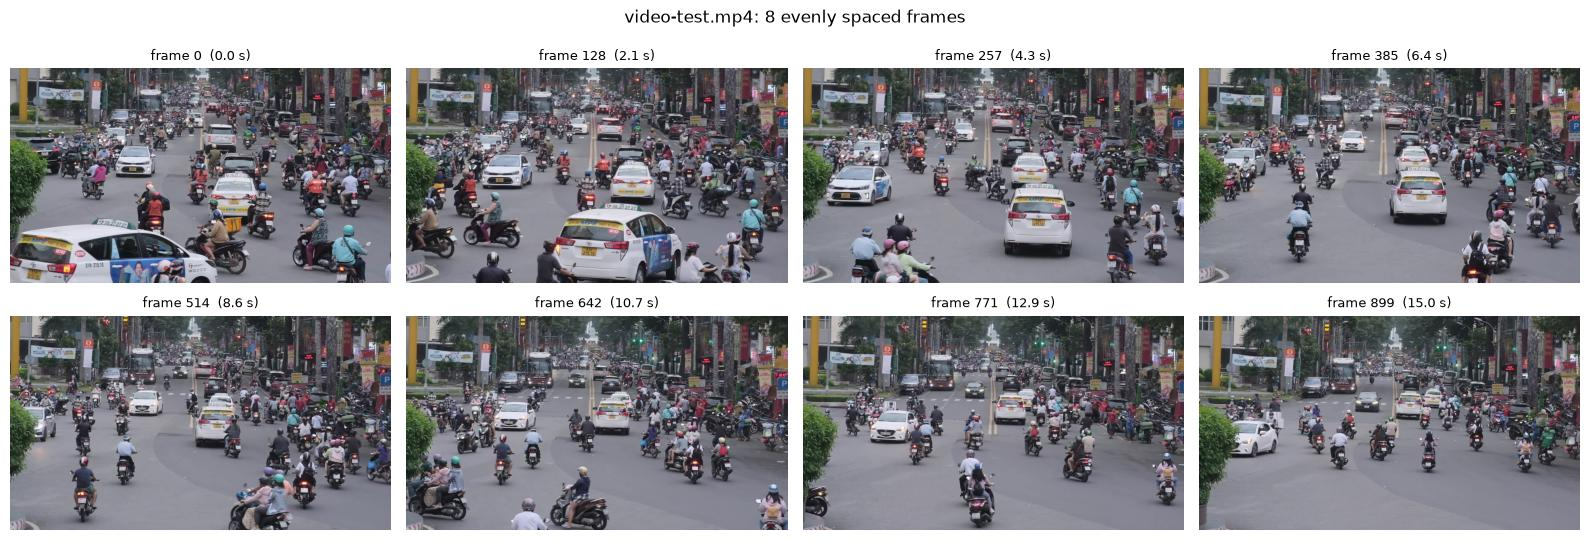

In [12]:
import math

import matplotlib.pyplot as plt


def show_frame_grid(frames: dict[int, np.ndarray], fps: float, title: str, columns: int = 4, save_path: Path | None = None):
    rows = math.ceil(len(frames) / columns)
    height, width = next(iter(frames.values())).shape[:2]
    fig, axes = plt.subplots(rows, columns, figsize=(4 * columns, 4 * columns * rows * height / width / columns + 0.6 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (index, frame) in zip(axes, sorted(frames.items())):
        ax.imshow(to_rgb(frame))
        ax.set_title(f"frame {index}  ({index / fps:.1f} s)", fontsize=9)
        ax.axis("off")
    for ax in axes[len(frames):]:
        ax.axis("off")
    fig.suptitle(title)
    fig.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, dpi=100)
    plt.show()


sample_fps = sample_reported["fps"]
sample_frame_count = sample_decoded["decoded_frame_count"]
grid_frames = read_frames_at(SAMPLE_VIDEO, evenly_spaced_indices(sample_frame_count, 8))
show_frame_grid(grid_frames, sample_fps, f"{SAMPLE_VIDEO.name}: 8 evenly spaced frames",
                save_path=OUTPUT_DIR / "sample_frame_grid.png")

A single frame at full size shows how much detail is available, for example whether license plates or the signal head could be legible.

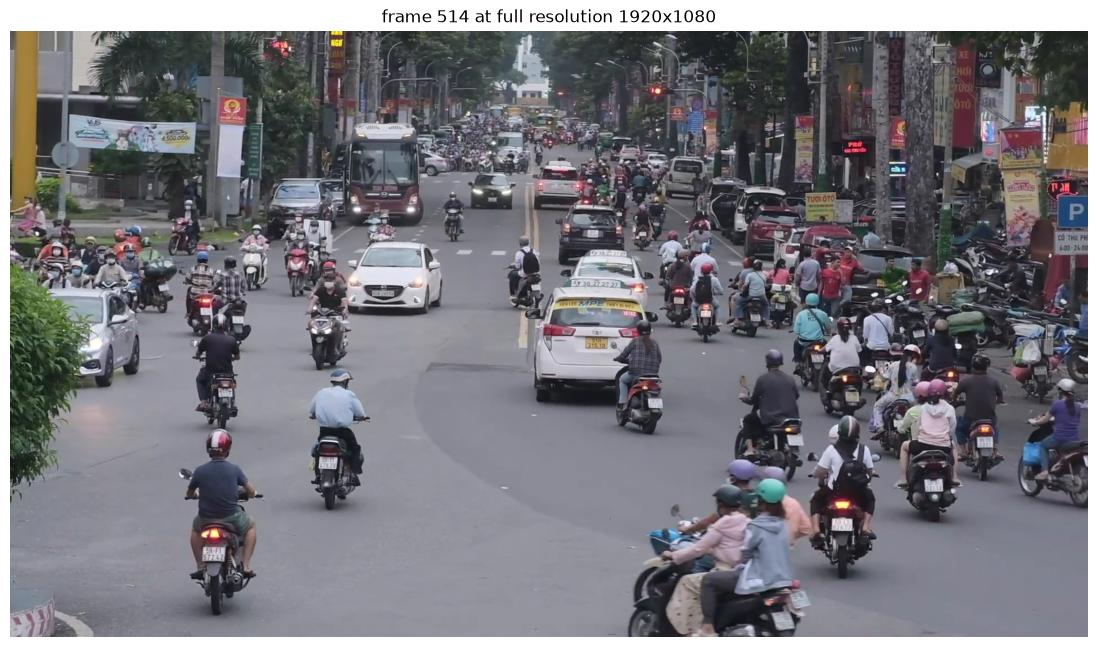

In [13]:
middle_index = sorted(grid_frames)[len(grid_frames) // 2]
middle_frame = grid_frames[middle_index]

fig, ax = plt.subplots(figsize=(14, 14 * middle_frame.shape[0] / middle_frame.shape[1]))
ax.imshow(to_rgb(middle_frame))
ax.set_title(f"frame {middle_index} at full resolution {middle_frame.shape[1]}x{middle_frame.shape[0]}")
ax.axis("off")
plt.show()

For the background and heatmap we sample 40 frames across the clip and downscale them to at most 960 px wide. The median is computed in floating point, and 40 full-resolution frames would need several GB of memory; scene layout does not need full resolution.

In [14]:
def downscale(frame: np.ndarray, max_width: int = 960) -> np.ndarray:
    height, width = frame.shape[:2]
    if width <= max_width:
        return frame
    scale = max_width / width
    return cv2.resize(frame, (max_width, round(height * scale)), interpolation=cv2.INTER_AREA)


background_indices = evenly_spaced_indices(sample_frame_count, 40)
background_frames = read_frames_at(SAMPLE_VIDEO, background_indices)
stack = np.stack([downscale(background_frames[i]) for i in sorted(background_frames)])
background = np.median(stack, axis=0).astype(np.uint8)

print("Frames in stack :", stack.shape[0], "| downscaled size:", stack.shape[2], "x", stack.shape[1])
assert cv2.imwrite(str(OUTPUT_DIR / "sample_static_background.png"), background)

Frames in stack : 40 | downscaled size: 960 x 540


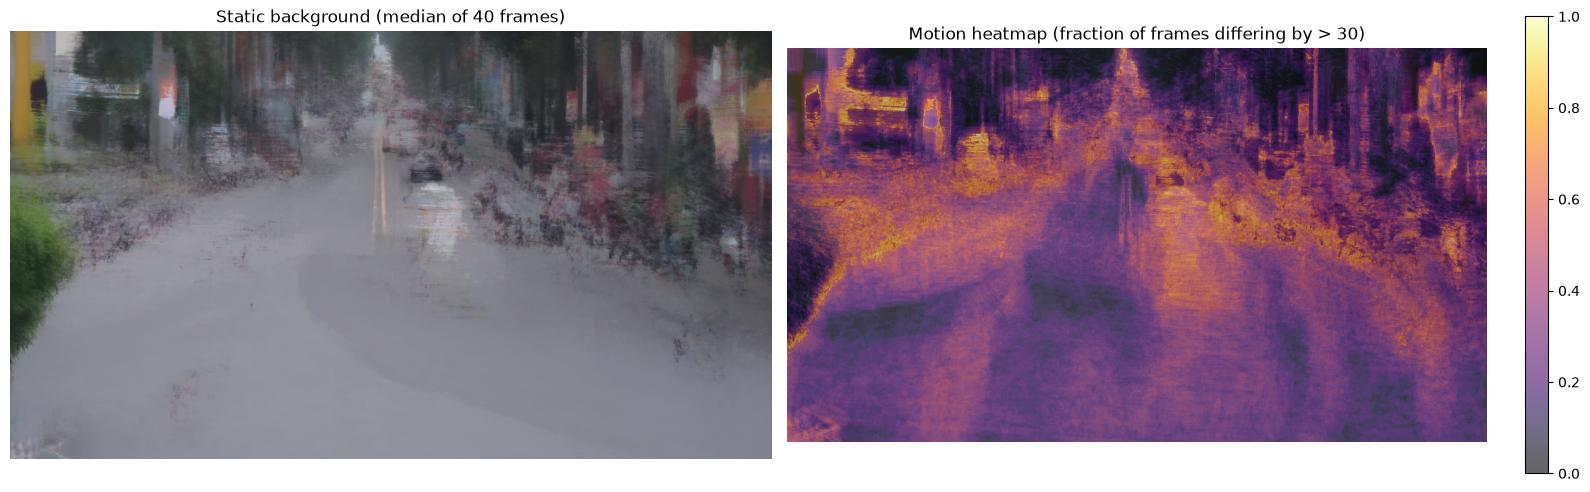

Pixels with motion in >5% of sampled frames: 96.1% of the image


In [15]:
MOTION_THRESHOLD = 30  # grey-level difference (0-255) counted as "different from background"

background_gray = cv2.cvtColor(background, cv2.COLOR_BGR2GRAY).astype(np.int16)
stack_gray = np.stack([cv2.cvtColor(f, cv2.COLOR_BGR2GRAY) for f in stack]).astype(np.int16)
motion_fraction = (np.abs(stack_gray - background_gray) > MOTION_THRESHOLD).mean(axis=0)

fig, axes = plt.subplots(1, 2, figsize=(16, 16 / 2 * background.shape[0] / background.shape[1] + 0.8))
axes[0].imshow(to_rgb(background))
axes[0].set_title("Static background (median of 40 frames)")
axes[1].imshow(to_rgb(background))
heat = axes[1].imshow(motion_fraction, cmap="inferno", alpha=0.6, vmin=0, vmax=max(motion_fraction.max(), 1e-6))
axes[1].set_title(f"Motion heatmap (fraction of frames differing by > {MOTION_THRESHOLD})")
fig.colorbar(heat, ax=axes[1], fraction=0.03)
for ax in axes:
    ax.axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sample_background_and_motion.png", dpi=100)
plt.show()

print(f"Pixels with motion in >5% of sampled frames: {(motion_fraction > 0.05).mean():.1%} of the image")

### Is the camera static?

The background above is blurred and the heatmap marks almost the whole image, including buildings and trees. Both suggest that the **camera itself moves**, which matters a lot: Notebook 04 will draw stop lines and regions in *pixel coordinates*, and those only stay valid if the camera is fixed.

We measure camera motion instead of guessing:

1. Take every 30th frame (~0.5 s apart).
2. Detect **ORB keypoints** (distinctive corners with binary descriptors) in each frame and in frame 0.
3. Match descriptors between each frame and frame 0.
4. Fit a **similarity transform** (shift, rotation, uniform scale) with **RANSAC**. Matches on moving vehicles disagree with the dominant camera motion and are rejected as outliers; the static scene (buildings, poles, road markings) forms the inliers.

We report how far the image **center** moves relative to frame 0, in full-resolution pixels. Shift and rotation are combined into that single displacement.

In [16]:
MOTION_STEP = 30
motion_indices = list(range(0, sample_frame_count, MOTION_STEP)) + [sample_frame_count - 1]
motion_frames = read_frames_at(SAMPLE_VIDEO, motion_indices)

orb = cv2.ORB_create(nfeatures=3000)
matcher = cv2.BFMatcher(cv2.NORM_HAMMING, crossCheck=True)


def to_small_gray(frame: np.ndarray) -> np.ndarray:
    return cv2.cvtColor(downscale(frame), cv2.COLOR_BGR2GRAY)


reference_gray = to_small_gray(motion_frames[0])
to_full_res = sample_reported["width"] / reference_gray.shape[1]
center = np.array([reference_gray.shape[1] / 2, reference_gray.shape[0] / 2, 1.0])
reference_kp, reference_des = orb.detectAndCompute(reference_gray, None)

camera_motion = []
for index in sorted(motion_frames)[1:]:
    kp, des = orb.detectAndCompute(to_small_gray(motion_frames[index]), None)
    matches = matcher.match(reference_des, des)
    src = np.float32([reference_kp[m.queryIdx].pt for m in matches])
    dst = np.float32([kp[m.trainIdx].pt for m in matches])
    transform, inliers = cv2.estimateAffinePartial2D(src, dst, method=cv2.RANSAC, ransacReprojThreshold=3.0)
    center_shift = (transform @ center - center[:2]) * to_full_res
    camera_motion.append({
        "frame": index,
        "time_s": round(index / sample_fps, 2),
        "center_dx_px": round(float(center_shift[0]), 1),
        "center_dy_px": round(float(center_shift[1]), 1),
        "scale": round(float(np.hypot(transform[0, 0], transform[1, 0])), 4),
        "rotation_deg": round(float(np.degrees(np.arctan2(transform[1, 0], transform[0, 0]))), 2),
        "inliers": int(inliers.sum()),
        "matches": len(matches),
    })

print("frame  time_s  dx_px   dy_px   scale   rot_deg  inliers/matches")
for m in camera_motion[::3] + [camera_motion[-1]]:
    print(f"{m['frame']:5d}  {m['time_s']:6.2f}  {m['center_dx_px']:6.1f}  {m['center_dy_px']:6.1f}  "
          f"{m['scale']:.4f}  {m['rotation_deg']:6.2f}  {m['inliers']}/{m['matches']}")

frame  time_s  dx_px   dy_px   scale   rot_deg  inliers/matches
   30    0.50    -9.0    -0.4  0.9998    0.04  161/1007
  120    2.00   -27.7    11.2  0.9998    0.10  120/964
  210    3.50   -41.9    11.3  0.9998    0.11  103/944
  300    5.01   -47.0    19.5  1.0000    0.11  104/907
  390    6.51   -41.9    29.2  0.9994    0.16  112/871
  480    8.01   -40.3    47.7  0.9989    0.24  113/877
  570    9.51   -40.9    61.1  0.9992    0.25  99/915
  660   11.01   -36.6    78.5  0.9993    0.33  103/901
  750   12.51   -17.0    90.5  0.9989    0.41  99/930
  840   14.01    -8.0    99.2  0.9991    0.40  82/925
  899   15.00    14.1   109.2  0.9985    0.86  100/862


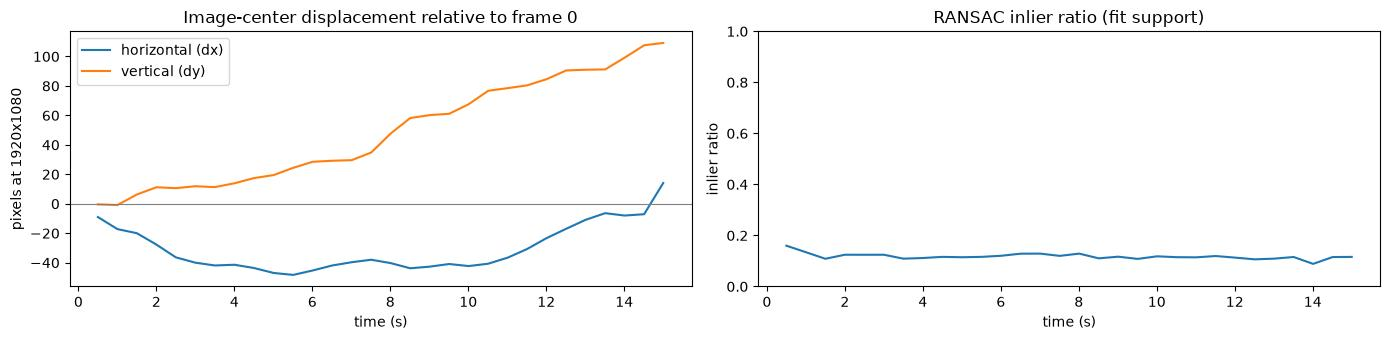

Maximum image-center displacement vs frame 0: 110 px (10.2% of frame height)
Scale range: 0.9985 - 1.0005
Inlier counts: 82 - 161


In [17]:
times = [m["time_s"] for m in camera_motion]
fig, axes = plt.subplots(1, 2, figsize=(14, 3.5))
axes[0].plot(times, [m["center_dx_px"] for m in camera_motion], label="horizontal (dx)")
axes[0].plot(times, [m["center_dy_px"] for m in camera_motion], label="vertical (dy)")
axes[0].axhline(0, color="grey", linewidth=0.8)
axes[0].set(xlabel="time (s)", ylabel="pixels at 1920x1080", title="Image-center displacement relative to frame 0")
axes[0].legend()
axes[1].plot(times, [m["inliers"] / m["matches"] for m in camera_motion])
axes[1].set(xlabel="time (s)", ylabel="inlier ratio", title="RANSAC inlier ratio (fit support)", ylim=(0, 1))
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sample_camera_motion.png", dpi=100)
plt.show()

max_shift = max(np.hypot(m["center_dx_px"], m["center_dy_px"]) for m in camera_motion)
print(f"Maximum image-center displacement vs frame 0: {max_shift:.0f} px "
      f"({max_shift / sample_reported['height']:.1%} of frame height)")
print(f"Scale range: {min(m['scale'] for m in camera_motion):.4f} - {max(m['scale'] for m in camera_motion):.4f}")
print(f"Inlier counts: {min(m['inliers'] for m in camera_motion)} - {max(m['inliers'] for m in camera_motion)}")

### Is a traffic signal visible?

A red-light rule needs the signal state at the moment a vehicle crosses the stop line. In the frames above, small signal heads are visible near the top centre, at the far intersection. We crop that region at full resolution at five moments across the clip.

The crop is generous because the camera drifts. This is a visual inspection only; no automatic state recognition is attempted yet.

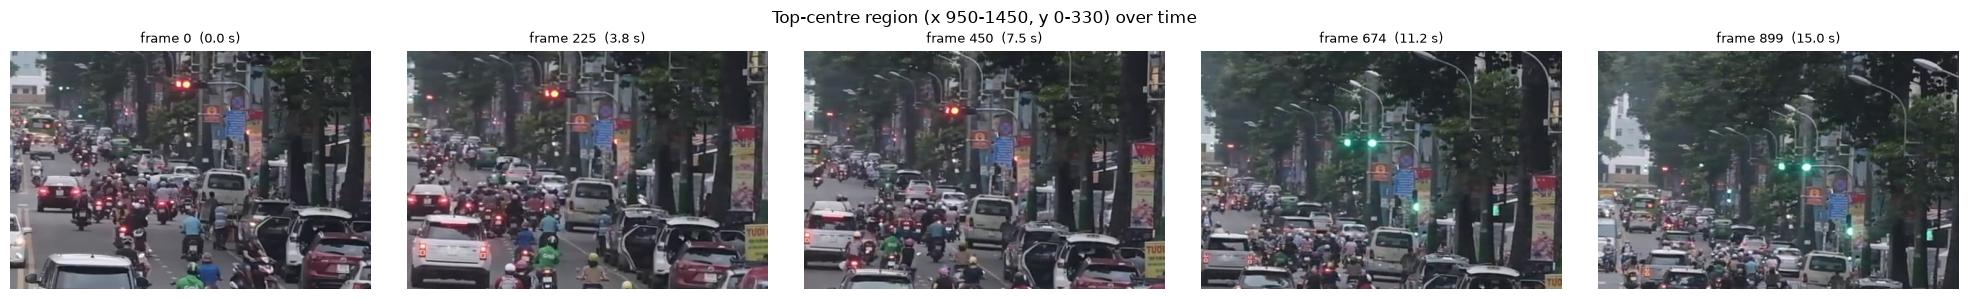

In [18]:
SIGNAL_REGION = (slice(0, 330), slice(950, 1450))  # (rows, cols) at 1920x1080, chosen by inspection

signal_indices = evenly_spaced_indices(sample_frame_count, 5)
signal_frames = read_frames_at(SAMPLE_VIDEO, signal_indices)

fig, axes = plt.subplots(1, len(signal_frames), figsize=(4 * len(signal_frames), 3))
for ax, (index, frame) in zip(axes, sorted(signal_frames.items())):
    ax.imshow(to_rgb(frame[SIGNAL_REGION]))
    ax.set_title(f"frame {index}  ({index / sample_fps:.1f} s)", fontsize=9)
    ax.axis("off")
fig.suptitle("Top-centre region (x 950-1450, y 0-330) over time")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "sample_signal_region.png", dpi=100)
plt.show()

### Other clips

A short look at the additional clips, to know what other scenarios exist. Twelve frames per clip are shown, because objects in `car-detection.mp4` appear only intermittently.

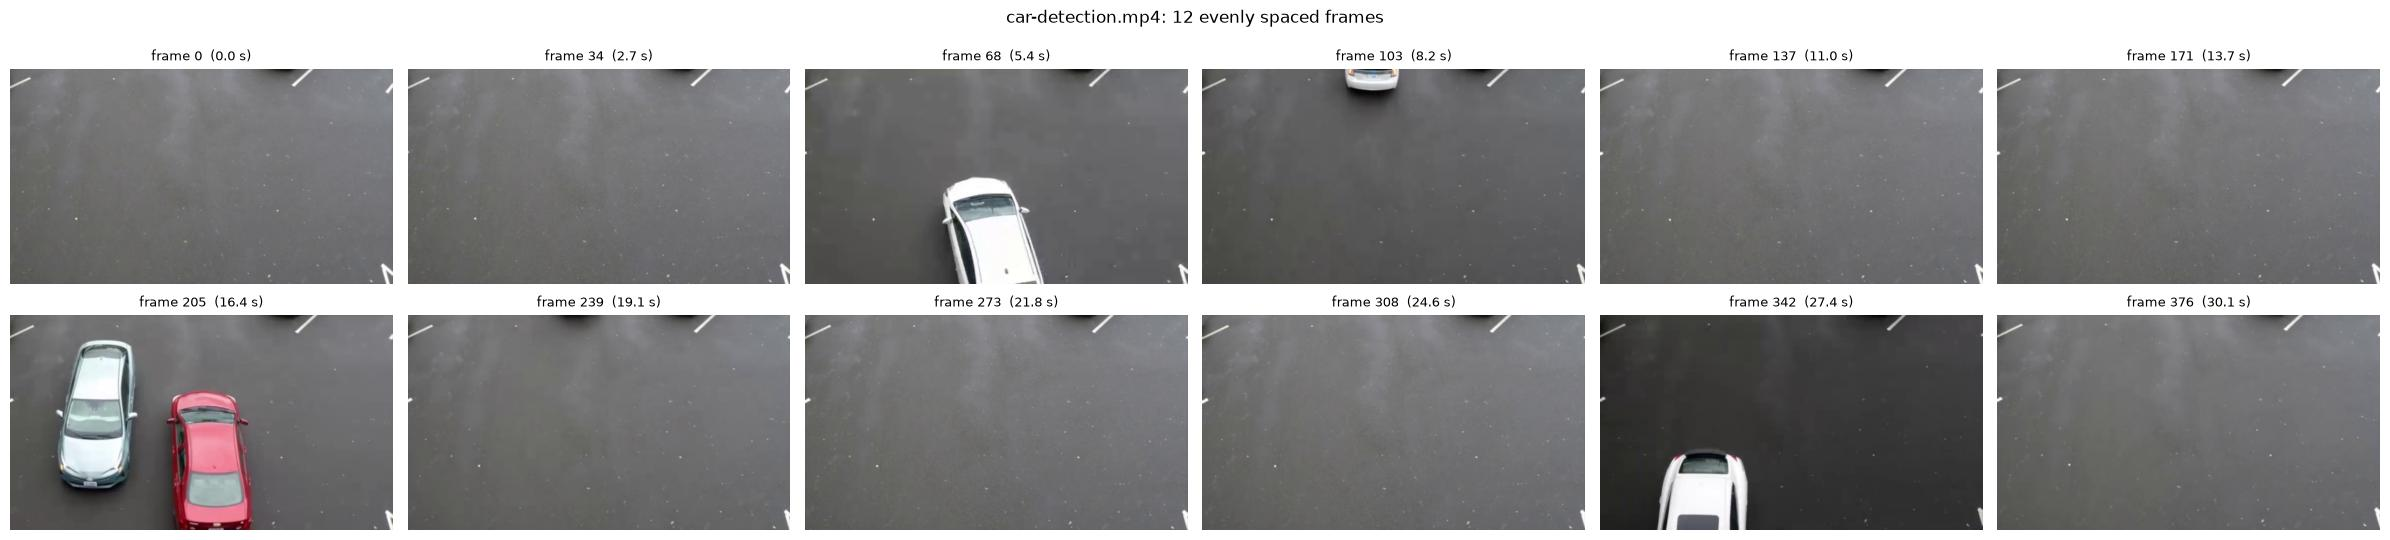

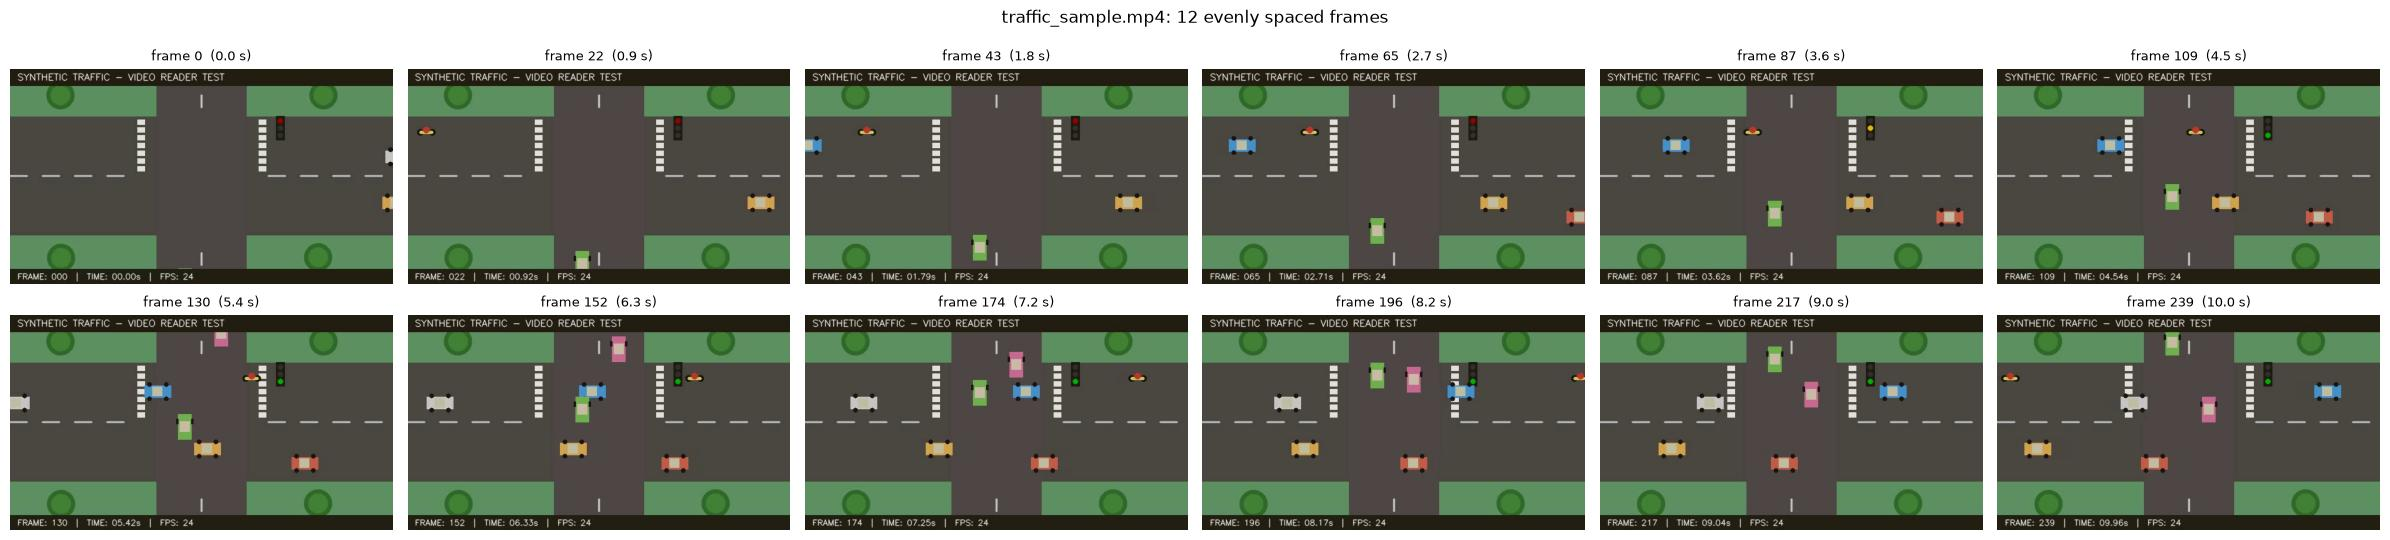

In [19]:
for record in inventory:
    path = PROJECT_ROOT / record["file"]
    if path == SAMPLE_VIDEO:
        continue
    frames = read_frames_at(path, evenly_spaced_indices(record["decoded_frame_count"], 12))
    show_frame_grid(frames, record["fps"], f"{path.name}: 12 evenly spaced frames", columns=6,
                    save_path=OUTPUT_DIR / f"{path.stem}_frame_grid.png")

## 6. Observations

Observations are split into **measured** facts, taken from the cell outputs above, and **visual** observations, made by inspecting the sampled frames. Visual observations cover only the frames shown, not every frame.

### Primary sample — `data/video-test.mp4`

**Measured**

- H.264 in MP4, 1920×1080, 59.94 FPS, 900 frames, 15.02 s.
- The decoded frame count equals the reported count. Every frame is 1080×1920×3 `uint8`.
- Sequential CPU decoding runs at roughly 300 frames/s on the development machine, about 5× real time. The exact figure varies between runs and machines.
- **The camera is not static.** Relative to frame 0, the image center drifts smoothly by up to ≈110 px (≈10% of the frame height), mostly vertically.
  - Scale stays at ≈1.0, so there is no zoom. Rotation stays below 1°.
  - The estimate has modest support: about 10–16% of descriptor matches are RANSAC inliers, because most of the image is moving traffic.
  - Three independent signs agree with it: the smooth trend, the blurred median background, and the drifting position of the signal head in the crops above.

**Visual**

- **Scene.** An urban street in Vietnam (Vietnamese signage and plate formats), filmed from an elevated position looking along the road toward a signalized intersection in the distance. Overcast daylight with slight haze.
- **Directions.** A two-way road divided by a yellow center line.
  - Most near-field vehicles travel **away from the camera**: we see rear views, tail lights, and rear plates.
  - The far-left lanes carry **oncoming** traffic, with headlights visible.
- **Objects.** Motorcycles dominate and are very dense. There are also cars, taxis, and buses. Pedestrians and parked motorcycles and cars line the right side.
- **Occlusion and scale.** Motorcycles occlude each other heavily. Object size ranges from large in the near field to a few pixels at the far intersection.
- **Traffic signal.**
  - Signal heads at the far intersection face the camera, so they govern the away-from-camera traffic.
  - In the sampled crops they show **red at 0.0, 3.8 and 7.5 s** and **green at 11.2 and 15.0 s**. The red→green transition therefore lies between 7.5 s and 11.2 s.
  - The lamps are only roughly 10–20 px across. This is a visual estimate.
- **Stop line.** Not identifiable in the inspected frames. The intersection is far away and crowded.
- **License plates.** Rear plates of the nearest motorcycles and cars are visible. Plates of distant vehicles are not legible. Legibility has not been measured.

### Other clips

- **`data/traffic_sample.mp4`** — a **synthetic** top-down animation labelled "SYNTHETIC TRAFFIC — VIDEO READER TEST" (640×360, 24 FPS, 10 s).
  - It shows an intersection with crosswalks, a traffic light that changes red → yellow → green, and cars on both axes.
  - The **frame number, timestamp and FPS are burned into each frame**. That makes it a ground truth for checking frame indices, timestamps and seeking in Notebook 01, and a controlled scenario for testing rule logic later.
  - Because it is synthetic, it is not suitable for evaluating real detectors.
- **`data/car-detection.mp4`** — an overhead, apparently static view of an asphalt surface (768×432, 12.5 FPS, 30.16 s).
  - Cars pass through intermittently; many frames are empty.
  - Brightness changes between frames (frame 342 is visibly darker).
  - There are no signals or lane structure. It is useful for detector and tracker sanity checks on a simple scene, not for violation detection.

## 7. Suitability for violation detection

For each candidate violation type, the table lists the evidence the rule would need and what `video-test.mp4` actually provides. It is a preliminary assessment; the final choice is made in Notebooks 04–05.

| Violation type | Evidence required | What the sample provides | Preliminary assessment |
| --- | --- | --- | --- |
| Red-light running | Signal state governing the vehicle; stop-line position; crossing time | Signal visible, faces the away-from-camera flow, changes red → green. Stop line not identified. Crossings happen far away, with small, occluded vehicles. Camera drifts. | Ingredients present, but hardest. Needs stop-line identification, signal-state recognition on ~10–20 px lamps, and drift compensation. |
| Wrong-way driving | Allowed direction per side/lane; trajectories | Two-way road with a visible center line; both directions observable in the near field. | Evidence is the easiest to observe. **No wrong-way instance has been verified yet**; with zero positives, recall cannot be evaluated. |
| Lane / center-line violation | Lane boundaries that stay valid over time; trajectories | Center line visible, but it shifts by up to ≈110 px because of camera drift. | Possible only with drift compensation. No occurrence verified yet. |

**Key consequence.** Any rule that uses fixed scene geometry (stop lines, lane lines, regions of interest) cannot use static pixel coordinates on this clip. Notebook 04 must either register every frame to a reference frame (for example, with the same keypoint-matching approach used above), restrict experiments to a stable segment, or obtain footage from a fixed camera.

## Validation

Hard checks are conditions the rest of the project depends on; a failure stops the notebook. Informational checks are recorded but do not fail the run, because a mismatch there is a property of the file to keep in mind rather than an access failure.

In [20]:
sample_shape = tuple(sample_decoded["frame_shapes"][0]) if sample_decoded["frame_shapes"] else None

hard_checks = {
    "Python >= 3.11": sys.version_info >= (3, 11),
    "Required packages installed": all(v is not None for k, v in package_versions.items()),
    "OpenCV built with FFMPEG video backend": ffmpeg_enabled,
    "Primary sample video exists": SAMPLE_VIDEO.is_file(),
    "Primary sample decodes at least one frame": sample_decoded["decoded_frame_count"] > 0,
    "All sample frames share one shape": len(sample_decoded["frame_shapes"]) == 1,
    "Frame shape matches reported width x height": sample_shape == (sample_reported["height"], sample_reported["width"], 3),
    "Frames are 8-bit (uint8)": sample_decoded["frame_dtypes"] == ["uint8"],
    "Every video in data/ decodes": all(r["decoded_frame_count"] > 0 for r in inventory),
}
info_checks = {
    f"{r['file']}: decoded count == reported count": r["decoded_frame_count"] == r["reported_frame_count"]
    for r in inventory
}

for name, passed in hard_checks.items():
    print(f"[{'PASS' if passed else 'FAIL'}] {name}")
for name, passed in info_checks.items():
    print(f"[{'INFO-OK' if passed else 'INFO-DIFF'}] {name}")

assert all(hard_checks.values()), "One or more hard checks failed - see above"

[PASS] Python >= 3.11
[PASS] Required packages installed
[PASS] OpenCV built with FFMPEG video backend
[PASS] Primary sample video exists
[PASS] Primary sample decodes at least one frame
[PASS] All sample frames share one shape
[PASS] Frame shape matches reported width x height
[PASS] Frames are 8-bit (uint8)
[PASS] Every video in data/ decodes
[INFO-OK] data/car-detection.mp4: decoded count == reported count
[INFO-OK] data/traffic_sample.mp4: decoded count == reported count
[INFO-OK] data/video-test.mp4: decoded count == reported count


## Save the inventory

The environment and video facts are written to a JSON file so later notebooks, or a later re-run on the GPU server, can be compared against them without re-executing this notebook.

In [21]:
import json
from datetime import datetime, timezone

report = {
    "generated_at_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {
        "python": sys.version.split()[0],
        "platform": platform.platform(),
        "packages": package_versions,
        "opencv_ffmpeg": ffmpeg_enabled,
        "nvidia_gpus": gpus,
        "torch_installed": torch_installed,
    },
    "primary_sample": sample_reported["file"],
    "primary_sample_camera_motion": camera_motion,
    "videos": inventory,
}
inventory_path = OUTPUT_DIR / "dataset_inventory.json"
inventory_path.write_text(json.dumps(report, indent=2))

reloaded = json.loads(inventory_path.read_text())
assert reloaded["videos"] == json.loads(json.dumps(inventory)), "Round-trip mismatch"
print("Wrote", inventory_path.relative_to(PROJECT_ROOT))

Wrote outputs/00_environment_and_dataset/dataset_inventory.json


## Limitations

- **One machine.** Environment facts and decoding speed were measured on the development machine, which is CPU only. The GPU server environment has not been created or verified yet.
- **Camera-motion estimate.** The keypoint-based estimate has low inlier support (≈10–16%). Treat the magnitude as approximate; the existence and direction of the drift are well supported.
- **Sampled inspection.** Scene, signal and plate observations come from sampled frames only, and short events between samples may be missed. The signal transition time is known only to lie between 7.5 s and 11.2 s.
- **Not yet verified.** Timestamp consistency (presentation timestamps), seek accuracy, and variable frame rate are not checked here; they belong to Notebook 01.
- **Short clip.** A single 15-second clip is too little data for a meaningful evaluation (Notebook 09). More footage, ideally from a fixed camera, will be needed.
- **Provenance.** The source and usage permission of the clips are not documented here. They should be confirmed before any results are shared (see *Responsible Use* in the README).

## Conclusion

**Completion criteria**

- *The environment can be reproduced:* **met on the development machine.**
  - `environment.yml` pins Python 3.11, and `pyproject.toml` declares the packages.
  - The notebook runs top to bottom from a clean `Python (tvd)` kernel, and all hard checks pass.
  - Reproduction on the GPU server is still pending.
- *The video can be accessed reliably:* **met.**
  - All 900 frames of the primary sample decode, with one consistent shape and a frame count that matches the container.
  - The other two clips decode completely as well.

**Readiness.** The environment and data access are ready for Notebook 01. The most important finding for later notebooks is that **the primary sample's camera drifts by up to ≈110 px**. It does not block video reading, but it must be handled before any scene configuration (Notebook 04).

**Next steps**

- **Notebook 01** — verify frame indices, timestamps and seeking. Use the burned-in frame/time overlay of `traffic_sample.mp4` as ground truth, then apply the verified access patterns to `video-test.mp4`.
- **Before Notebook 02** — create the conda environment on the GPU server, re-run this notebook there, and add the PyTorch build that matches the server's CUDA version.